# Ornstein-Uhlenbeck

$$dX_t=0.5(0-X_t)\,dt+0.3\,dB_t^P.$$

Repeat the Black-Scholes workflow with $N=100000$, $T=1$, $X_0=1$, and seed 3.
Compare Method 1, Method 2, and ODE2 for drift. Use each recovered drift for its own noise recovery and final SSISDE fit. The diffusion regression
parameters and the final ElasticNet parameters are tuned. ODE2 uses the known initial spatial slope.

Compare three final SSISDE fits, using noise from Method 1, Method 2 and ODE2. Each fit uses the same degree-5 libraries, seven-fold cross-validation and seven elastic-net mixing values. The final table reports noise, drift and diffusion errors.


In [1]:
from pathlib import Path
import os
import sys

if not (3, 10) <= sys.version_info[:2] < (3, 13):
    raise RuntimeError("The original dependency pins require Python 3.10–3.12; use the local .venv or a compatible Colab runtime.")

def _find_project():
    for candidate in [Path.cwd(), *Path.cwd().parents, Path('/content/SSISDE')]:
        if (candidate / 'models/stochastic_sindy.py').is_file() and (candidate / 'requirements.txt').is_file():
            return candidate
    return None

PROJECT_ROOT = _find_project()
if PROJECT_ROOT is None:
    import importlib.util
    try:
        _in_colab = importlib.util.find_spec('google.colab') is not None
    except ModuleNotFoundError:
        _in_colab = False
    if not _in_colab:
        raise FileNotFoundError("Open this notebook from the SSISDE checkout so its Python scripts are available.")

    def _download_private_project():
        from getpass import getpass
        from io import BytesIO
        from urllib.request import Request, urlopen
        from zipfile import ZipFile
        token = getpass('GitHub token (read-only Contents access to SSISDE): ')
        try:
            request = Request(
                'https://api.github.com/repos/munawarali93/SSISDE/zipball/main',
                headers={'Authorization': f'Bearer {token}', 'Accept': 'application/vnd.github+json'},
            )
            with urlopen(request, timeout=120) as response:
                archive_bytes = response.read()
        finally:
            token = None
            request = None
        destination = Path('/content/SSISDE')
        with ZipFile(BytesIO(archive_bytes)) as archive:
            for member in archive.infolist():
                relative = Path(*Path(member.filename).parts[1:])
                if member.is_dir() or not relative.parts:
                    continue
                target = (destination / relative).resolve()
                if not target.is_relative_to(destination.resolve()):
                    raise ValueError('Unsafe archive path')
                target.parent.mkdir(parents=True, exist_ok=True)
                target.write_bytes(archive.read(member))
        return destination

    PROJECT_ROOT = _download_private_project()

os.chdir(PROJECT_ROOT / 'experiments/ou')
print(f'Project: {PROJECT_ROOT}')
print(f'Python: {sys.version.split()[0]}')

sys.path.insert(0, str(PROJECT_ROOT))
RESULTS = PROJECT_ROOT / 'outputs/ou'
RESULTS.mkdir(parents=True, exist_ok=True)


Project: /Users/munawarali/Documents/GitHub/SSISDE
Python: 3.11.13


##Install libraries

In [2]:
# Install into the selected kernel before importing scientific libraries.
# The four original version pins are retained in requirements.txt.
import subprocess
subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-r', str(PROJECT_ROOT / 'requirements.txt')])



[notice] A new release of pip is available: 25.1.1 -> 26.2.1
[notice] To update, run: /Users/munawarali/Documents/GitHub/SSISDE/.venv/bin/python -m pip install --upgrade pip


0

##Import libraries

In [3]:
import numpy as np
import math
import matplotlib.pyplot as plt
import pysindy as ps
import random
import iisignature
from sklearn import linear_model
from sklearn.metrics import mean_squared_error
from tqdm import tqdm
from sklearn.linear_model import Lasso, ElasticNet
from sklearn.model_selection import TimeSeriesSplit
import json
from threadpoolctl import threadpool_limits
from models.diffusion import fit_diffusion


/Users/munawarali/Documents/GitHub/SSISDE/.venv/lib/python3.11/site-packages/pysindy/__init__.py:1: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import DistributionNotFound


##Defining parameters and simulating noise

In [4]:
from data_generation.processes import generate_ou as generate_data
N, T, S0, seed = 100000, 1.0, 1.0, 3
kappa, theta, sigm = 0.5, 0.0, 0.3
exact_mu_coefficients = [kappa * theta, -kappa]
exact_sigma_coefficients = [sigm]
t, dt, S_, W_, mu_exact_, sigma_exact_ = generate_data(N, T, S0, seed, kappa=kappa, theta=theta, sigm=sigm)
fine_dt = dt


##Simulating primary processes

## $$dS_t = \mu(S_t)dt + \sigma(S_t)dB_t$$

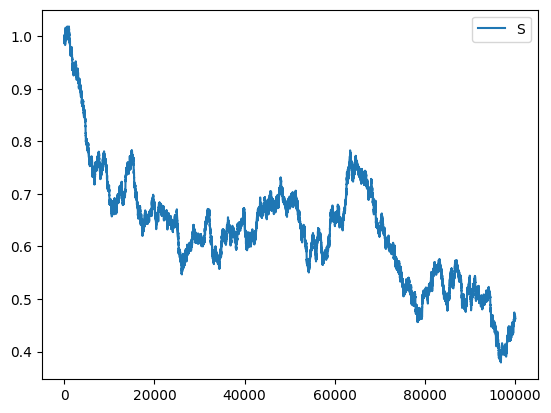

In [5]:
plt.plot(S_, label="S")
plt.legend()
plt.show()

##compute quadratic variation

  0%|          | 0/100000 [00:00<?, ?it/s]

 10%|▉         | 9741/100000 [00:00<00:00, 97392.45it/s]

 19%|█▉        | 19481/100000 [00:00<00:01, 71317.00it/s]

 27%|██▋       | 27025/100000 [00:00<00:01, 60823.16it/s]

 33%|███▎      | 33390/100000 [00:00<00:01, 53575.73it/s]

...

 93%|█████████▎| 93021/100000 [00:03<00:00, 18848.01it/s]

 95%|█████████▍| 94908/100000 [00:03<00:00, 18480.51it/s]

 97%|█████████▋| 96758/100000 [00:03<00:00, 18215.96it/s]

 99%|█████████▊| 98581/100000 [00:03<00:00, 18001.62it/s]

100%|██████████| 100000/100000 [00:03<00:00, 27824.48it/s]

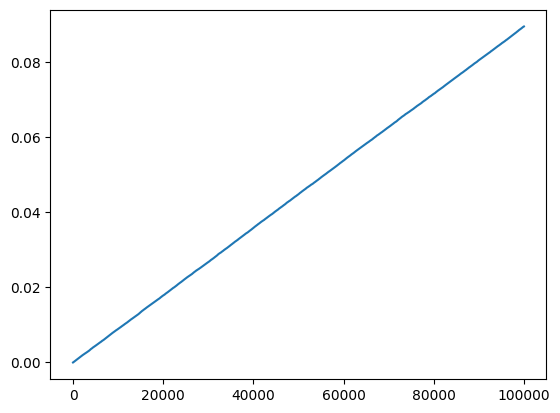

In [6]:
from models.diffusion import estimate_quadratic_variation
QV, dQV, diff_method = estimate_quadratic_variation(S_, t)
plt.plot(QV)

## Approximating $\sigma$

Use the existing degree-4 variance library. Select SR3 settings on the last
20% of observations, then refit on the full path. The true diffusion is used
only to report error. All subsequent stages follow Black-Scholes.

In [7]:
thresholds = [0.1, 0.3, 1.0, 3.0]
nus = [0.1, 0.5, 2.0]
model, sigma_settings, sigma_search = fit_diffusion(S_, t, dQV, thresholds, nus)
sigma_equation = model.equations(precision=8)[0]
print('sigma^2(X) =', sigma_equation)
print(sigma_settings)
(RESULTS / 'diffusion_tuning.json').write_text(json.dumps(sigma_search, indent=2))

sigma^2(X) = 0.08940725 1
{'threshold': 3.0, 'nu': 2.0, 'validation_mse': 0.013210960133907384, 'max_iter': 10000, 'tol': 1e-08, 'terms': 1, 'converged': True, 'full_fit_converged': True}


2014

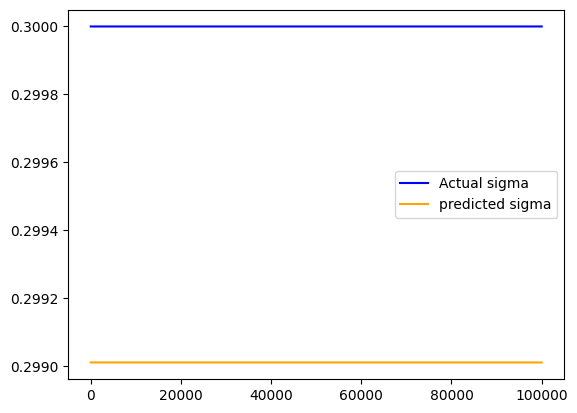

In [8]:
sigma_pred_ = np.sqrt(model.predict(S_.reshape(-1, 1)))
sigma_pred_ = np.array(sigma_pred_)
plt.plot(sigma_exact_, label="Actual sigma",color="blue")
plt.plot(sigma_pred_,label="predicted sigma", color="orange")
plt.legend()
plt.show()

In [9]:
from models.diffusion import diffusion_derivatives
sigma_prime_, sigma_2prime_, sigma_3prime_ = diffusion_derivatives(sigma_pred_, S_, diff_method)


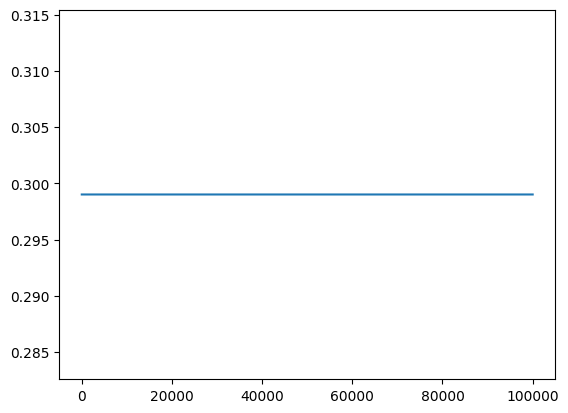

In [10]:
plt.plot(sigma_pred_)

##Q Brownian motion

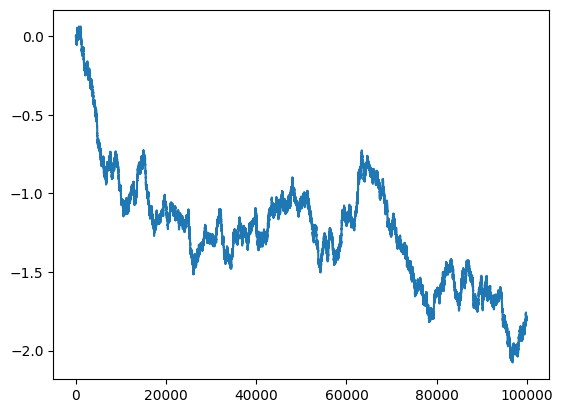

In [11]:
from models.noise import recover_q_noise
BQ_ = recover_q_noise(S_, sigma_pred_)
plt.plot(BQ_)

#Fit signature model

In [12]:
keep_cols = [0, 1, 3, 4, 5, 13]

  0%|          | 0/1000 [00:00<?, ?it/s]

  6%|▌         | 55/1000 [00:00<00:01, 548.69it/s]

 21%|██▏       | 213/1000 [00:00<00:00, 1151.44it/s]

 40%|███▉      | 399/1000 [00:00<00:00, 1472.73it/s]

 55%|█████▌    | 552/1000 [00:00<00:00, 1492.20it/s]

 70%|███████   | 702/1000 [00:00<00:00, 1400.17it/s]

 84%|████████▍ | 843/1000 [00:00<00:00, 1299.95it/s]

 99%|█████████▉| 990/1000 [00:00<00:00, 1350.81it/s]

100%|██████████| 1000/1000 [00:00<00:00, 1329.77it/s]

3.3863417071574716e-05

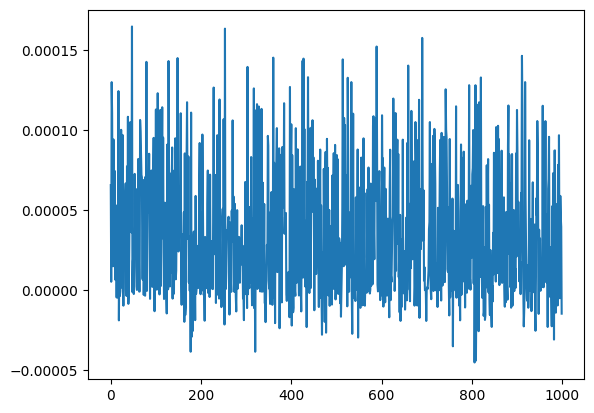

In [13]:
from models.drift import fit_signature
M = 100
K = int(N/M)
l21 = fit_signature(S_, BQ_, t, keep_cols, M)
plt.plot(l21)
np.mean(l21)

In [14]:
from data_generation.coarse_graining import coarse_grain
sigma_pred, mu_exact, S, BQ, W, sigma_exact = coarse_grain(
    S_, BQ_, W_, mu_exact_, sigma_exact_, sigma_pred_, M, K,
)


In [15]:
from models.diffusion import coarse_diffusion_derivatives
sigma_prime, sigma_2prime, sigma_3prime = coarse_diffusion_derivatives(sigma_pred, S, diff_method)


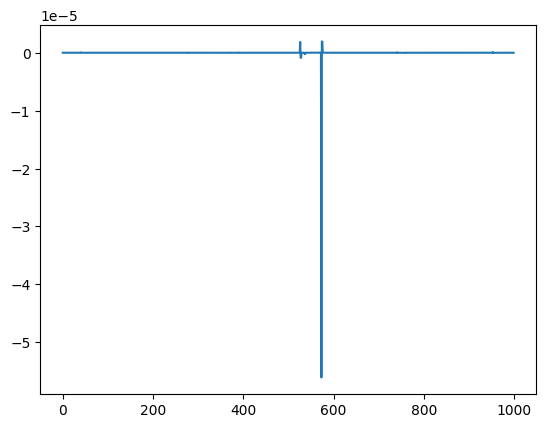

In [16]:
plt.plot(sigma_2prime)

## Predicting $\mu(X_t)$ by tuncating up to level-2 of iterated integrals

In [17]:
from models.drift import drift_coefficients
mu_0, a, b, b_ = drift_coefficients(mu_exact, sigma_pred, sigma_prime, sigma_2prime, l21)


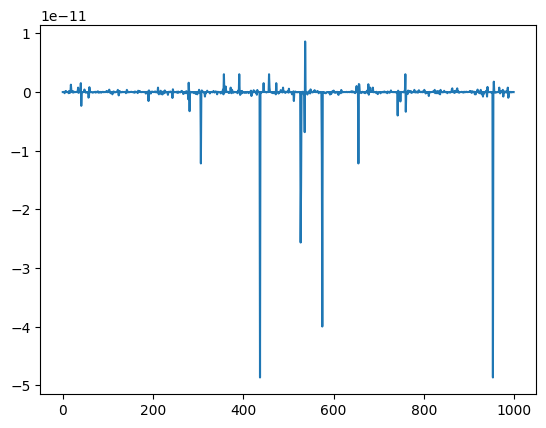

In [18]:
#plt.plot(b)
plt.plot(a)

In [19]:
from models.drift import recover_drift
mu_pred1, mu_pred2 = recover_drift(S, a, b, b_, mu_0)


## Drift recovery from ODE2

Use the same ODE2 recurrence as Black-Scholes. Supply the initial drift and
the known initial spatial slope for this process. This is a drift comparison;
noise recovery below uses Method 1.

In [20]:
lambda_0 = -kappa
from models.drift import recover_drift_ode2
mu_pred11, lamda_pred = recover_drift_ode2(S, sigma_pred, sigma_prime, sigma_2prime, mu_0, lambda_0)


In [21]:
ode2_drift_mse = mean_squared_error(mu_exact, mu_pred11)
print(f"ODE2 drift MSE: {ode2_drift_mse:.5f}")
print(f"ODE2 drift RMSE: {np.sqrt(ode2_drift_mse):.5f}")


ODE2 drift MSE: 0.00000
ODE2 drift RMSE: 0.00000


## Drift comparison across all methods

Method 1: drift RMSE = 0.19270
Method 2: drift RMSE = 0.19259
ODE2: drift RMSE = 0.00000


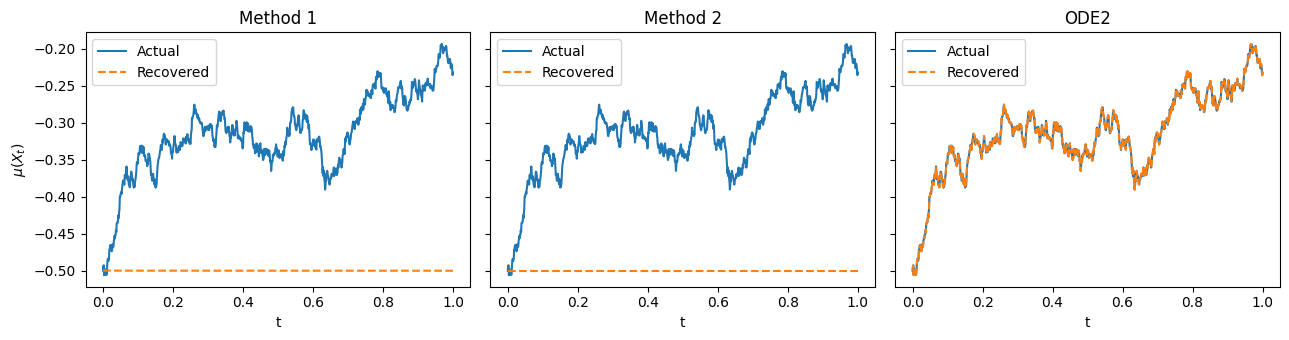

In [22]:
t_ = np.linspace(0, T, K)
drift_estimates = {'Method 1': mu_pred1, 'Method 2': mu_pred2, 'ODE2': mu_pred11}
drift_rmse = {}
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5), sharey=True)
for ax, (name, estimate) in zip(axes, drift_estimates.items()):
    drift_rmse[name] = float(np.sqrt(np.mean((estimate - mu_exact)**2)))
    ax.plot(t_, mu_exact, label='Actual')
    ax.plot(t_, estimate, '--', label='Recovered')
    ax.set_title(name)
    ax.set_xlabel('t')
    ax.legend()
    print(f"{name}: drift RMSE = {drift_rmse[name]:.5f}")
axes[0].set_ylabel(r'$\mu(X_t)$')
fig.tight_layout()
fig.savefig('drift_comparison_OU.png', dpi=200)
plt.show()


##Predicting P-Brownian motion

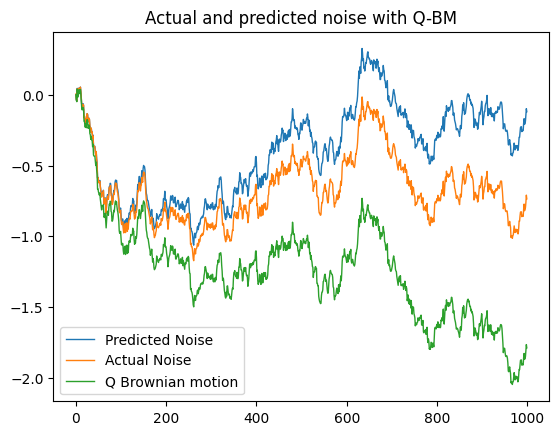

In [23]:
from models.noise import recover_p_noise
model = "Psi_approx_OU"
BP, dt, t = recover_p_noise(BQ, mu_pred1, sigma_pred, T)
plt.plot(BP, label="Predicted Noise", linewidth=1)
plt.plot(W, label="Actual Noise", linewidth=1)
plt.plot(BQ, label="Q Brownian motion", linewidth=1)
plt.title("Actual and predicted noise with Q-BM")
plt.legend()
plt.show()

### Drift from Method 1

MSE: 0.00000
μ(X) = -0.50031 + 0.00031*X
σ(X) = 0.29901
[CV best] alpha=0.00087, l1_ratio (rho)=0.40000


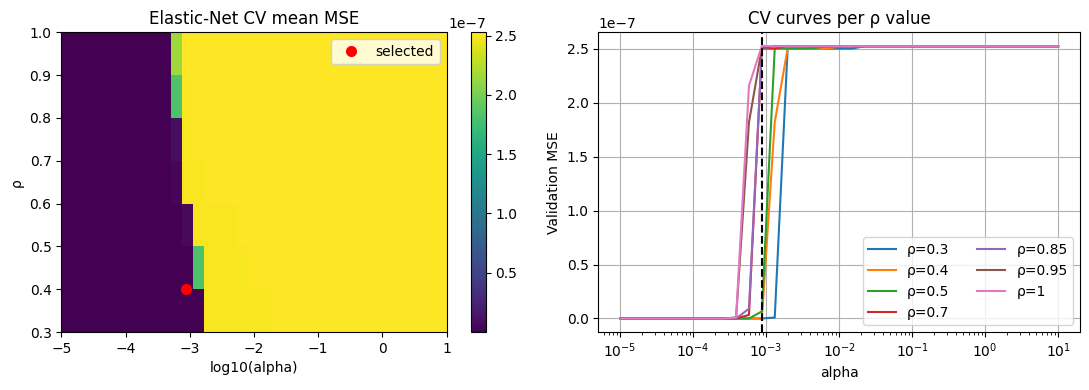

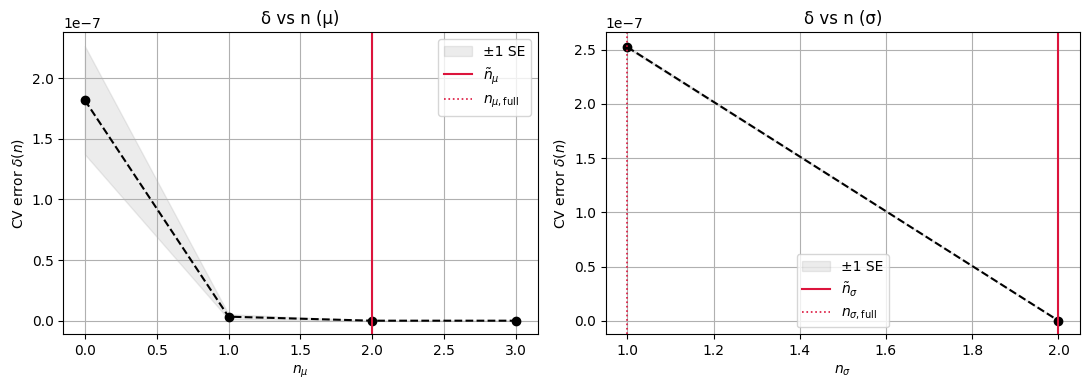

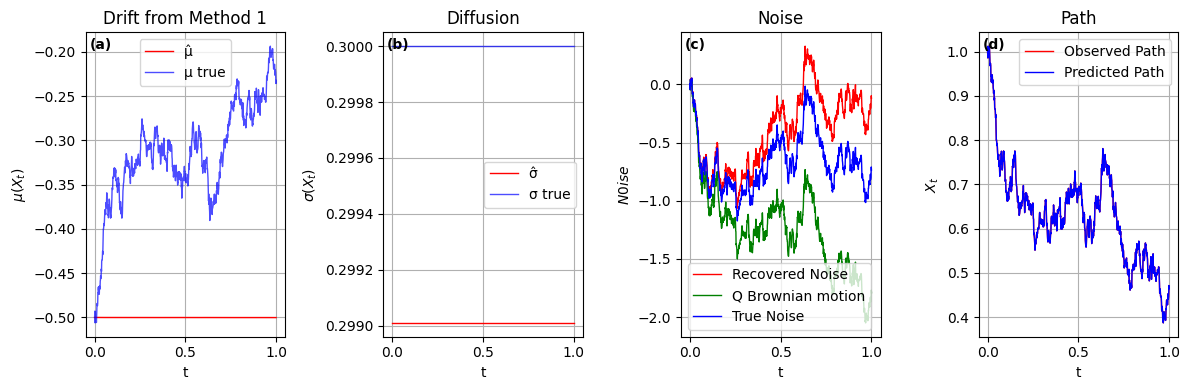

### Drift from Method 2

MSE: 0.00000
μ(X) = -0.50000
σ(X) = 0.29901
[CV best] alpha=0.00087, l1_ratio (rho)=0.40000


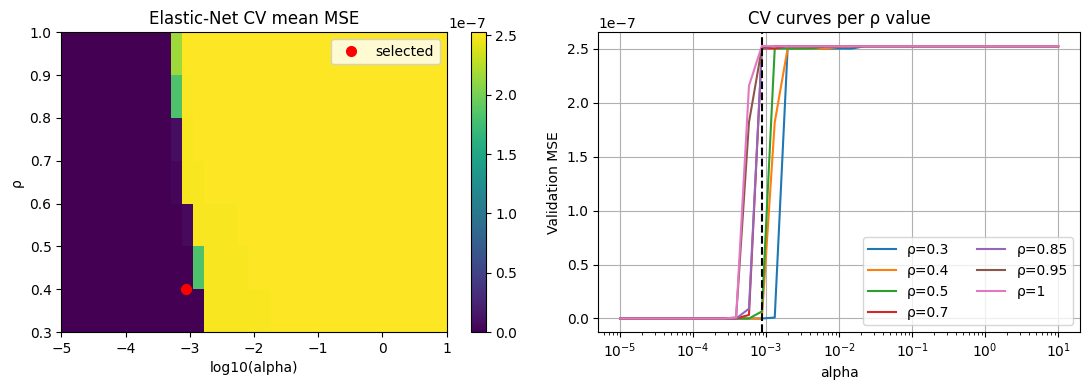

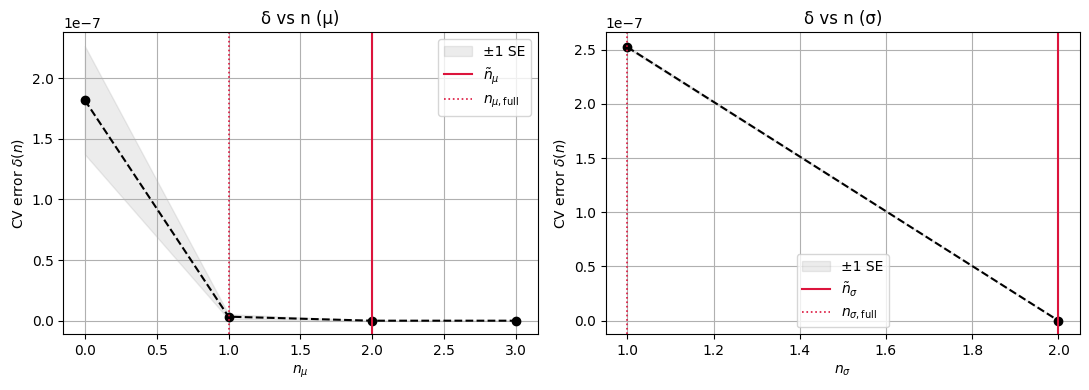

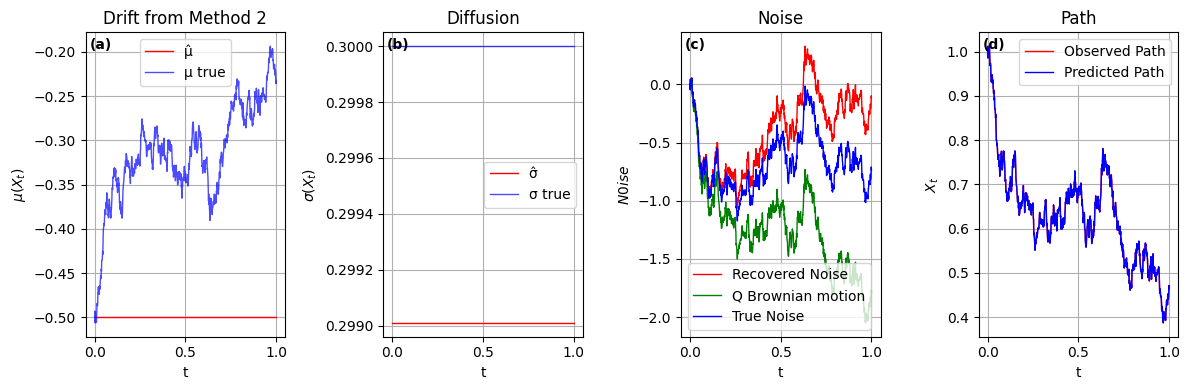

### Drift from ODE2

MSE: 0.00000
μ(X) = -0.50000*X
σ(X) = 0.29901
[CV best] alpha=0.00017, l1_ratio (rho)=0.40000


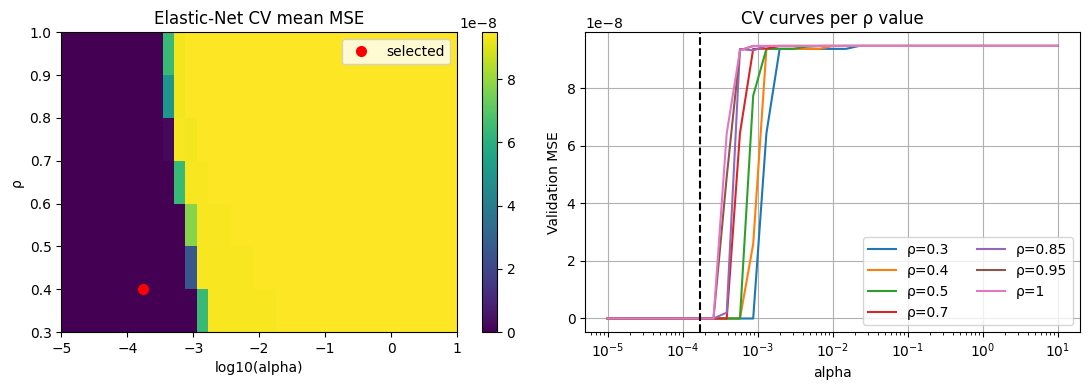

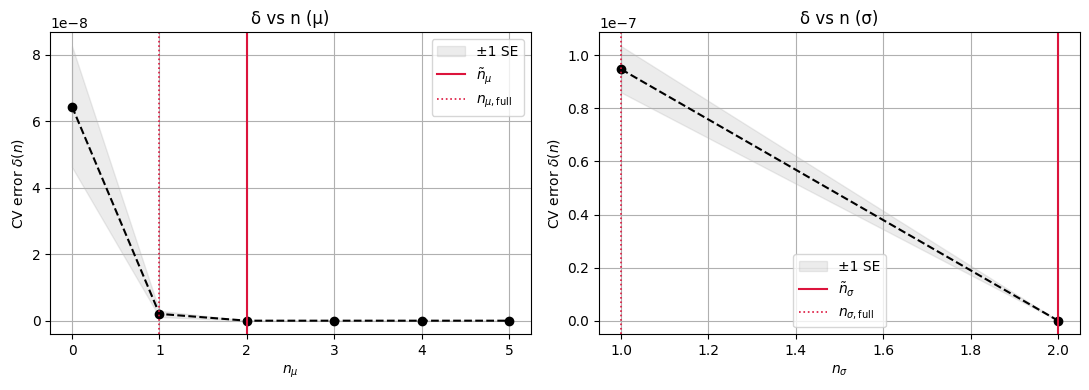

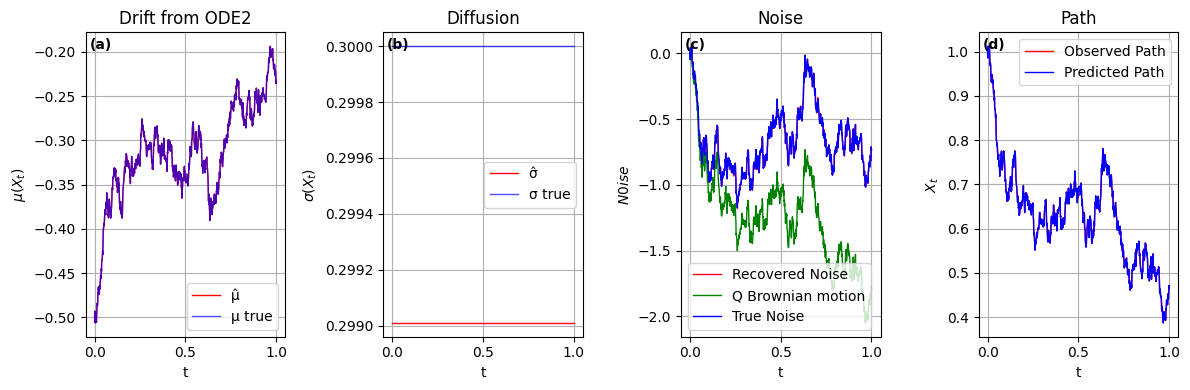

| Noise from | Noise RMSE | SSISDE drift RMSE | SSISDE diffusion RMSE |
|---|---:|---:|---:|
| Method 1 | 0.32017 | 0.19271 | 0.00099 |
| Method 2 | 0.31997 | 0.19259 | 0.00099 |
| ODE2 | 0.00386 | 0.00000 | 0.00099 |

In [24]:
from models.stochastic_sindy import StochSINDy
from models.noise import recover_p_noise
from threadpoolctl import threadpool_limits
from IPython.display import Markdown, display
import json

# Check the exact polynomial metadata against the simulated coefficients.
np.testing.assert_allclose(np.polynomial.polynomial.polyval(S, exact_mu_coefficients), mu_exact)
np.testing.assert_allclose(np.polynomial.polynomial.polyval(S, exact_sigma_coefficients), sigma_exact)
(RESULTS / "model_truth.json").write_text(json.dumps({
    "mu_coefficients": exact_mu_coefficients,
    "sigma_coefficients": exact_sigma_coefficients,
}, indent=2, allow_nan=False))

recovered_drifts = {"Method 1": mu_pred1, "Method 2": mu_pred2, "ODE2": mu_pred11}
identifiers, noise_paths, ssisde_comparison, comparison_paths = {}, {}, {}, {}

for method_name, recovered_drift in recovered_drifts.items():
    method_key = method_name.lower().replace(" ", "_")
    BP_method, dt_method, _ = recover_p_noise(BQ, recovered_drift, sigma_pred, T)
    noise_paths[method_name] = BP_method
    identifier_method = StochSINDy(
        mu_deg=5, si_deg=5,
        pen="elasticnet",
        use_cv=True, k=7,
        alphas=np.geomspace(1e-5, 1e1, 35),
        rhos=[0.3, 0.4, 0.5, 0.7, 0.85, 0.95, 1.0],
        use_1se=True,
    )
    with threadpool_limits(limits=1):
        identifier_method.fit(S, BP_method, dt_method)
    identifiers[method_name] = identifier_method
    output_prefix = f"{model}_{method_key}"
    display(Markdown(f"### Drift from {method_name}"))
    identifier_method.show()
    identifier_method.plot_cv(output_prefix=output_prefix)
    identifier_method.plot_size(count_bias=True, output_prefix=output_prefix)
    identifier_method.plot_results(
        S, BP_method, BQ, W, mu_true=mu_exact, si_true=sigma_exact,
        output_prefix=output_prefix, drift_title=f"Drift from {method_name}",
    )
    mu_fit = identifier_method.mu(S)
    sigma_fit = identifier_method.si(S)
    ssisde_comparison[method_name] = {
        "input_drift_rmse": float(np.sqrt(np.mean((recovered_drift - mu_exact)**2))),
        "noise_rmse": float(np.sqrt(np.mean((BP_method - W)**2))),
        "drift_rmse": float(np.sqrt(np.mean((mu_fit - mu_exact)**2))),
        "diffusion_rmse": float(np.sqrt(np.mean((sigma_fit - sigma_exact)**2))),
        "increment_mse": identifier_method.mse,
        "mu": identifier_method._fmt_poly(identifier_method.mu_c),
        "sigma": identifier_method._fmt_poly(identifier_method.si_c),
        "mu_coefficients": identifier_method.mu_c.tolist(),
        "sigma_coefficients": identifier_method.si_c.tolist(),
        "mu_coefficients_unrounded": identifier_method.mu_c_unrounded.tolist(),
        "sigma_coefficients_unrounded": identifier_method.si_c_unrounded.tolist(),
        "coefficient_decimals": identifier_method.coefficient_decimals,
        "increment_mse_unrounded": identifier_method.mse_unrounded,
        "alpha": identifier_method.best_a,
        "rho": identifier_method.best_r,
    }
    comparison_paths[f"BP_{method_key}"] = BP_method
    comparison_paths[f"input_drift_{method_key}"] = recovered_drift
    comparison_paths[f"mu_fit_{method_key}"] = mu_fit
    comparison_paths[f"sigma_fit_{method_key}"] = sigma_fit

(RESULTS / "ssisde_comparison.json").write_text(json.dumps(ssisde_comparison, indent=2, allow_nan=False))
np.savez_compressed(RESULTS / "ssisde_comparison_paths.npz", S=S, BQ=BQ, W=W,
                    mu_exact=mu_exact, sigma_exact=sigma_exact, sigma_pred=sigma_pred,
                    dt=dt, **comparison_paths)
rows = ["| Noise from | Noise RMSE | SSISDE drift RMSE | SSISDE diffusion RMSE |",
        "|---|---:|---:|---:|"]
for method_name, values in ssisde_comparison.items():
    rows.append(f"| {method_name} | {values['noise_rmse']:.5f} | "
                f"{values['drift_rmse']:.5f} | {values['diffusion_rmse']:.5f} |")
display(Markdown("\n".join(rows)))
identifier = identifiers["Method 1"]


In [25]:
def rmse(estimate, actual):
    return float(np.sqrt(np.mean((np.asarray(estimate).ravel() - np.asarray(actual).ravel())**2)))

results = {
    'ssisde_comparison': ssisde_comparison,
    'experiment': 'Ornstein-Uhlenbeck', 'workflow': 'Black-Scholes',
    'seed': seed, 'samples': N, 'T': T, 'X0': S0,
    'fine_dt': fine_dt, 'coarse_dt': dt, 'coarse_step': M,
    'sigma_settings': sigma_settings, 'sigma_squared_equation': sigma_equation,
    'sigma_rmse': rmse(sigma_pred_, sigma_exact_),
    'supplied_initial_drift': float(mu_0), 'supplied_initial_slope': float(lambda_0),
    'drift_rmse': {'Method 1': rmse(mu_pred1, mu_exact),
                   'Method 2': rmse(mu_pred2, mu_exact),
                   'ODE2': rmse(mu_pred11, mu_exact)},
    'noise_method': 'Method 1', 'noise_rmse': rmse(BP, W),
    'ssisde': {'mu': identifier._fmt_poly(identifier.mu_c),
               'sigma': identifier._fmt_poly(identifier.si_c),
               'drift_rmse': rmse(identifier.mu(S), mu_exact),
               'diffusion_rmse': rmse(identifier.si(S), sigma_exact),
               'increment_mse': identifier.mse,
               'alpha': identifier.best_a, 'rho': identifier.best_r},
}
(RESULTS / 'results.json').write_text(json.dumps(results, indent=2, allow_nan=False))
np.savez_compressed(RESULTS / 'paths.npz', S=S, W=W, BQ=BQ, BP=BP,
                    mu_exact=mu_exact, sigma_exact=sigma_exact, sigma_pred=sigma_pred,
                    mu_method1=mu_pred1, mu_method2=mu_pred2, mu_ode2=mu_pred11)
print(json.dumps(results, indent=2))

{
  "ssisde_comparison": {
    "Method 1": {
      "input_drift_rmse": 0.1927032779841842,
      "noise_rmse": 0.32016789347829056,
      "drift_rmse": 0.19270500701900345,
      "diffusion_rmse": 0.0009899999999999909,
      "increment_mse": 2.9626362319113937e-16,
      "mu": "-0.50031 + 0.00031*X",
      "sigma": "0.29901",
      "mu_coefficients": [
        -0.50031,
        0.00031,
        0.0,
        0.0,
        0.0,
        0.0
      ],
      "sigma_coefficients": [
        0.29901,
        0.0,
        0.0,
        0.0,
        0.0,
        0.0
      ],
      "mu_coefficients_unrounded": [
        -0.5003105858792598,
        0.0003139624215735781,
        0.0,
        0.0,
        0.0,
        0.0
      ],
      "sigma_coefficients_unrounded": [
        0.2990105540092259,
        -1.7231700083461586e-07,
        0.0,
        0.0,
        0.0,
        0.0
      ],
      "coefficient_decimals": 5,
      "increment_mse_unrounded": 8.959455053603182e-17,
      "alpha": 0.00087